<p style="text-align:center"><img src="../images/04_05_disease_mapping.png" alt="Disease Mapping and Bayesian Smoothing" width="100%"></p>


# Disease Mapping and Bayesian Smoothing



This folder is Part 5 of Module 04. A county with few cases can post a rate that looks extreme only because the count is small. Eleven notebooks replace that raw rate with a smoothed one and say how much the smoothing moved it. The running example is diabetes in 217 northeastern counties (`diabetes_northeast.shp`), with a simulation whose true risk is known.

- **Disease Mapping and Bayesian Smoothing.** This notebook. Says why the raw rate misleads and lists the tools that follow.
- **Motivation: the Small-Area Estimation Problem.** Shows, with the county numbers, that small populations make noisy rates.
- **Data and Making the Problem Visible.** Builds the county file, a simulation with known truth, and the cancer point data.
- **Raw Estimates and Naïve Inference.** Computes the crude rate, the standardised mortality ratio, and an exact Poisson interval.
- **Empirical Bayes Smoothing.** Shrinks rates toward a global mean, a normal mean, and a mean borrowed from neighbours.
- **Spatial Bayesian Models: BYM and BYM2.** Fits the Besag-York-Mollié model, with a spatial effect and an unstructured effect, plus covariates and the chance of exceeding a threshold.
- **MCMC Implementation.** Runs the two sampling backends, checks the diagnostics, and shows what under-sampling does.
- **Comparing and Evaluating Smoothing Methods.** Scores the smoothed maps against the known truth and asks what smoothing does to apparent clusters.
- **Shrinkage Assessment and Interpretation.** Finds which counties move the most, and why.
- **Reporting, Interpretation and Ethics.** Covers uncertainty, suppression of small counts, and the ecological fallacy.
- **Hand-offs and Exercises.** Carries the maps forward to Parts 6 and 9, and works five problems.

**Library:** `geolattice.spatial_statistics.bayes`


## Overview

Parts 2 and 4 both worked with `Dia_pct`, diagnosed diabetes prevalence, as if every county's reported rate
were equally trustworthy. It is not: a rate computed from a population of 5,000 is far noisier than the same
rate computed from a population of 2 million, purely from sampling variability, and Part 4, Chapter 4.7 already
previewed why that matters for cluster detection specifically. Part 5 is the full treatment: **why** small-area
rates are unstable, and the two families of tools, empirical Bayes and fully Bayesian spatial smoothing, that
fix it by *borrowing strength*, either across all areas or across neighbours.

| Step | What we do |
|------|------------|
| Objectives | State precisely what this Part will build and validate |
| Package map | `expected_counts`, `smr`, the `eb_*` family, `BYM`: what each does and when to reach for it |
| MCMC backends | The dependency-free built-in sampler (always available) vs. PyMC/NUTS (optional, faster mixing, needed for BYM2) |
| First look | One raw rate, one smoothed rate, side by side, before any of the machinery is explained |


## API overview

```
- Queen
- expected_counts, smr, eb_gamma_poisson, BYM, pymc_available
```


## Setup

Locate the repository root, import the spatial-statistics helpers, and point `DATA` at the example files.

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
import geolattice.spatial_statistics
from geolattice.viz import apply_map_style

from geolattice.spatial_statistics.weights import Queen
from geolattice.spatial_statistics.bayes import expected_counts, smr, eb_gamma_poisson, BYM, pymc_available

apply_map_style()
C = {"blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a", "orange": "#dd6b20",
     "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b"}

print(f"geolattice.spatial_statistics  : version {geolattice.spatial_statistics.__version__}")
print(f"PyMC available: {pymc_available()}  (this Part runs either way)")


geolattice.spatial_statistics  : version 0.3.49


/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


PyMC available: True  (this Part runs either way)


## Objectives

By the end of Part 5:

1. **Understand why small-area rates are unstable**: a direct consequence of Poisson sampling variance
   (Chapter 5.2), made visible with a funnel plot rather than a paragraph of assertion.
2. **Implement empirical Bayes smoothing**: global (gamma-Poisson), normal/James-Stein, and spatial (local
   neighbourhood) variants (Chapter 5.5), and know when each is the more sensible choice.
3. **Understand and fit the BYM model**: the standard fully Bayesian spatial disease-mapping model, with both
   its built-in dependency-free sampler and, optionally, PyMC/NUTS (Chapters 5.6-5.7).
4. **Compare raw and smoothed estimates**, both visually and against a known simulated truth (Chapter 5.8).
5. **Interpret shrinkage correctly**: which areas move, by how much, and toward what (Chapter 5.9).
6. **Report smoothed estimates responsibly**: uncertainty, small-cell suppression, the ecological fallacy
   (Chapter 5.10).


## What This Library Provides

| Need | Function | Chapter |
|---|---|---|
| Expected counts under indirect standardisation | `expected_counts` | 5.3 |
| Raw rate and its exact Poisson interval | `smr`, `smr_confidence_interval`, `excess_pvalue` | 5.4 |
| Funnel-plot control limits | `funnel_limits` | 5.4 |
| Global empirical Bayes (gamma-Poisson) | `eb_gamma_poisson` | 5.5 |
| Normal / James-Stein shrinkage | `eb_james_stein` | 5.5 |
| Spatial (neighbourhood) empirical Bayes | `eb_local` | 5.5 |
| Fully Bayesian BYM / BYM2 spatial smoothing | `BYM` | 5.6-5.7 |
| Simulation with known truth, and scoring | `simulate_relative_risk`, `simulate_counts`, `evaluate_smoothing` | 5.3, 5.8 |
| What smoothing changed, per area | `shrinkage_summary`, `BYM.shrinkage()` | 5.9 |

`BYM`'s `backend='gibbs'` (the default) is a blocked Gibbs/Metropolis sampler with **no extra dependencies**,
every notebook in this Part runs end to end without PyMC. `backend='pymc'` (or `'auto'`) uses NUTS, which mixes
faster and is required for the `model='bym2'` parametrisation; PyMC is installed in this environment
(confirmed above), so Chapters 5.6-5.7 use it directly for the comparison it enables, with every PyMC-only cell
clearly marked.


## A First Look

Before any theory: one variable, one raw rate, one smoothed rate, on the familiar 217 Northeast counties.


In [2]:
counties = gpd.read_file(DATA / "diabetes_northeast.shp")
w = Queen(counties, transform="binary")   # ICAR needs 0/1 adjacency, not row-standardised weights

O = counties["Dia_count"].to_numpy()
POP = counties["POP_Total"].to_numpy()
E = expected_counts(POP, observed=O)

raw = smr(O, E)
eb = eb_gamma_poisson(O, E, method="mle")

comparison = pd.DataFrame({
    "COUNTY": counties["COUNTY"], "POP_Total": POP, "raw_SMR": raw, "EB_smoothed": eb.estimate,
}).sort_values("POP_Total")
comparison.head(6)

,COUNTY,POP_Total,raw_SMR,EB_smoothed
89,Hamilton County,4444.4,1.319558,1.287119
142,Cameron County,4507.6,1.108308,1.101552
187,Sullivan County,6055.2,1.161339,1.151278
207,Essex County,6188.4,1.322808,1.298394
209,Grand Isle County,7082.2,1.002516,1.006446
157,Forest County,7221.8,1.015094,1.017969


Look at the smallest counties (top of the table, sorted by population): their raw SMR and EB-smoothed value
differ the most: exactly the counties Chapter 5.2 explains are noisiest to begin with. The largest counties
(bottom of the table, not shown here) barely move at all. This asymmetric response: small areas shrink more,
large areas barely change: is the entire mechanism Part 5 develops in full over the next ten chapters.


In [3]:
print(f"correlation(population, |raw - EB|): "
      f"{np.corrcoef(POP, np.abs(raw - eb.estimate))[0, 1]:.3f}  (negative: smaller counties move more)")

correlation(population, |raw - EB|): -0.225  (negative: smaller counties move more)


## Summary and Conclusions

This chapter set the objectives and map for Part 5.

### What we did

1. Stated the six concrete objectives this Part works toward.
2. Tabulated every function `geolattice.spatial_statistics.bayes` offers and which chapter develops it.
3. Confirmed both MCMC backends (built-in Gibbs, optional PyMC/NUTS) are available in this environment.
4. Took a first, informal look at raw vs. EB-smoothed rates, and confirmed the smallest counties move the most.

### Practical takeaways

- Every notebook in this Part is written to run with the dependency-free built-in sampler; where PyMC adds
  real value (BYM2, faster mixing, a cross-backend validation check) those cells are used directly here since
  PyMC is available, and are clearly marked so they can be skipped in an environment without it.
- The core empirical fact motivating this whole Part, small areas move more under smoothing, is already
  visible in one summary statistic, before any of the underlying theory is developed.

### Next steps

**Chapter 5.2 (Motivation: the Small-Area Estimation Problem)** makes the mechanism behind that asymmetry
explicit: Poisson sampling variance, and the funnel-plot picture of exactly how it depends on population size.


## Map


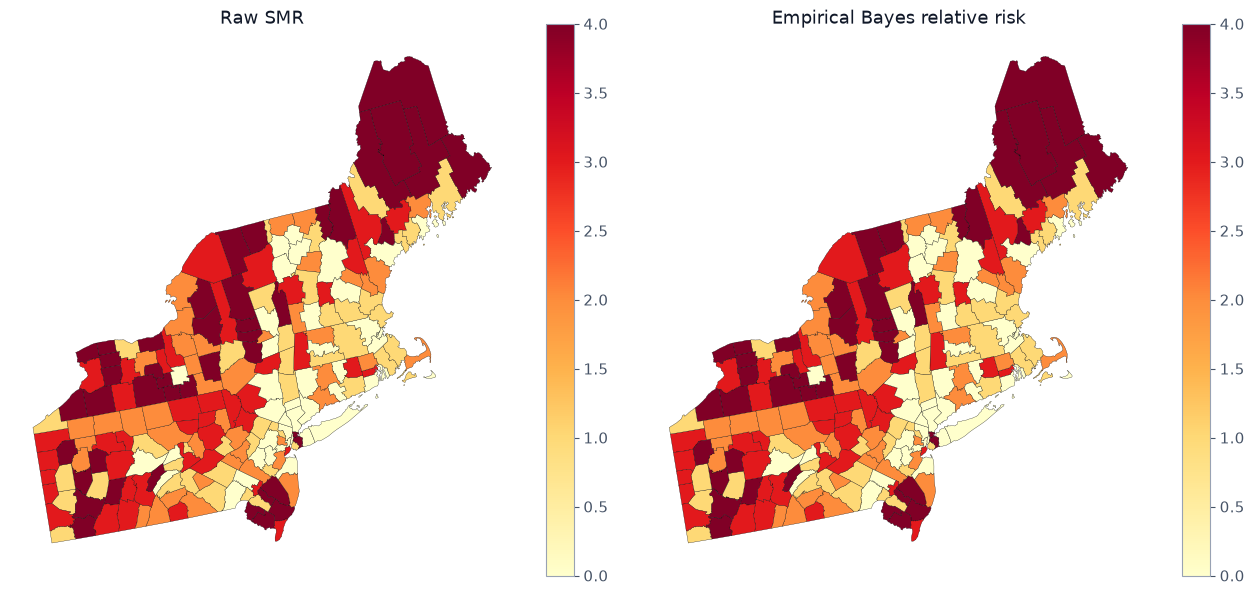

In [4]:
from geolattice.spatial_statistics.viz import choropleth

mapped = counties.copy()
mapped["raw_SMR"] = raw
mapped["EB"] = eb.estimate
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
choropleth(mapped, "raw_SMR", scheme="quantiles", k=5, ax=axes[0], cmap="YlOrRd")
choropleth(mapped, "EB", scheme="quantiles", k=5, ax=axes[1], cmap="YlOrRd")
axes[0].set_title("Raw SMR")
axes[1].set_title("Empirical Bayes relative risk")
plt.tight_layout()
plt.show()


## Further reading

### Textbooks

| Reference | Notes |
|---|---|
| Lawson, A. B. (2018). *Bayesian Disease Mapping: Hierarchical Modeling in Spatial Epidemiology* (3rd ed.). CRC Press. | The standard modern reference for this entire Part |
| Banerjee, S., Carlin, B. P. & Gelfand, A. E. (2014). *Hierarchical Modeling and Analysis for Spatial Data* (2nd ed.). CRC Press. | Rigorous treatment of the BYM model and its Bayesian foundations |
| Waller, L. A. & Gotway, C. A. (2004). *Applied Spatial Statistics for Public Health Data*. Wiley. | Accessible introduction to small-area estimation for health data |

### Key papers

| Paper | Contribution |
|---|---|
| Besag, J., York, J. & Mollié, A. (1991). Bayesian image restoration, with two applications in spatial statistics. *Annals of the Institute of Statistical Mathematics*, 43, 1-20. | Origin of the BYM model |
| Clayton, D. & Kaldor, J. (1987). Empirical Bayes estimates of age-standardized relative risks for use in disease mapping. *Biometrics*, 43, 671-681. | Origin of the empirical Bayes approach to disease mapping |

### In this library

| Object | Role |
|---|---|
| `geolattice.spatial_statistics.bayes.expected_counts`, `smr` | The raw quantities this whole Part starts from. Chapter 5.3-5.4 |
| `geolattice.spatial_statistics.bayes.eb_gamma_poisson`, `eb_james_stein`, `eb_local` | Empirical Bayes family. Chapter 5.5 |
| `geolattice.spatial_statistics.bayes.BYM` | Fully Bayesian spatial smoothing: Chapters 5.6-5.7 |
| `geolattice.spatial_statistics.bayes.pymc_available` | Checks whether the optional NUTS backend is installed |
